In [2]:
### Exporting Data

In [3]:
import pandas as pd
from pathlib import Path

file_path = Path("data.csv")

if file_path.is_file():
    print("The file exists!")
    df = pd.read_csv(file_path, encoding="latin1")
else:
    print("The file does not exist.")

The file exists!


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [6]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [7]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [8]:
### Cleaning

In [9]:
df_clean = df[(df['Quantity']>0) & (df['UnitPrice']>0)]

In [10]:
print(f"Original dataset rows: {df.shape[0]}")
print(f"Cleaned dataset rows:  {df_clean.shape[0]}")
print(f"Rows removed:          {df.shape[0] - df_clean.shape[0]}\n")

Original dataset rows: 541909
Cleaned dataset rows:  530104
Rows removed:          11805



In [11]:
df_clean.describe()

,Quantity,UnitPrice,CustomerID
count,530104.000000,530104.000000,397884.000000
mean,10.542037,3.907625,15294.423453
std,155.524124,35.915681,1713.141560
min,1.000000,0.001000,12346.000000
25%,1.000000,1.250000,13969.000000
50%,3.000000,2.080000,15159.000000
75%,10.000000,4.130000,16795.000000
max,80995.000000,13541.330000,18287.000000


In [12]:
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

In [13]:
df_clean['Total_Cost'] = df_clean['Quantity'] * df_clean['UnitPrice']

In [14]:
print(f"Data spans from: {df_clean['InvoiceDate'].min()} to {df_clean['InvoiceDate'].max()}")
print(f"last date in sheet is {df_clean['InvoiceDate'].max()}")

Data spans from: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
last date in sheet is 2011-12-09 12:50:00


In [15]:
df_clean

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Total_Cost
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [16]:
### RFM Framework

In [17]:
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1) # ading a day after the last sale in the sheet
snapshot_date

Timestamp('2011-12-10 12:50:00')

In [18]:
# regrouping data by customerID and calculating DFM values (usinf them as features)
rfm_data=df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date-x.max()).days, # Recency (days since last purchase)
    'InvoiceNo': 'nunique', #Frequency (total of unique purchases)
    'Total_Cost': 'sum' #Monetary(total money spent)
})

In [19]:
rfm_data.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'Total_Cost': 'Monetary'
}, inplace=True)

In [20]:
rfm_data

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
...,...,...,...
18280.0,278,1,180.60
18281.0,181,1,80.82
18282.0,8,2,178.05


In [21]:
rfm_data.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


In [22]:
### scaling 

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_data)

In [24]:
rfm_scaled

array([[ 2.33457414e+00, -4.25096503e-01,  8.35866818e+00],
       [-9.05340320e-01,  3.54416797e-01,  2.50966264e-01],
       [-1.75359593e-01, -3.53398530e-02, -2.85960063e-02],
       ...,
       [-8.45341904e-01, -2.95177619e-01, -2.08742313e-01],
       [-8.85340848e-01,  1.52368675e+00,  4.51854273e-03],
       [-4.95351144e-01, -1.65258736e-01, -2.41412739e-02]],
      shape=(4338, 3))

In [25]:
rfm_scaled=pd.DataFrame(rfm_scaled, index=rfm_data.index, columns=rfm_data.columns)

In [26]:
rfm_scaled

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.358668
12347.0,-0.905340,0.354417,0.250966
12348.0,-0.175360,-0.035340,-0.028596
12349.0,-0.735345,-0.425097,-0.033012
12350.0,2.174578,-0.425097,-0.191347
...,...,...,...
18280.0,1.854587,-0.425097,-0.208459
18281.0,0.884612,-0.425097,-0.219560
18282.0,-0.845342,-0.295178,-0.208742


In [27]:
### kmeans

In [28]:
from sklearn.cluster import KMeans
scores = []
for k in range(1,11):
    kmeans=KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    scores.append(kmeans.inertia_)

In [29]:
scores

[13014.000000000007,
 9012.6447253454,
 5439.304685942381,
 4092.144305254269,
 3118.2840089016963,
 2472.5745137484564,
 2022.4126705975725,
 1715.8148308150983,
 1445.6303271310012,
 1292.3411217070336]

In [30]:
### Elbow method graph

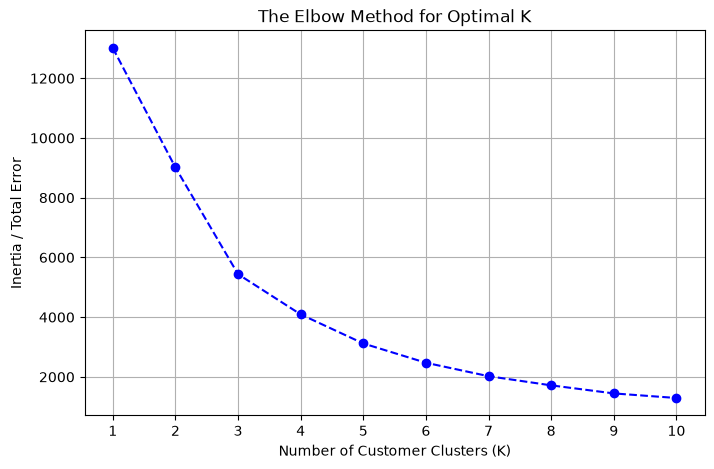

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), scores, marker='o', linestyle='--', color='b')
plt.title('The Elbow Method for Optimal K')
plt.xlabel('Number of Customer Clusters (K)')
plt.ylabel('Inertia / Total Error')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [32]:
### choosing k=3
k=3

In [33]:
final_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

In [34]:
customer_clusters = final_kmeans.fit_predict(rfm_scaled)

In [35]:
rfm_data['Cluster'] = customer_clusters

In [36]:
rfm_data

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,0
...,...,...,...,...
18280.0,278,1,180.60,0
18281.0,181,1,80.82,0
18282.0,8,2,178.05,1


In [37]:
rfm_data.describe()

,Recency,Frequency,Monetary,Cluster
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460,0.756570
std,100.014169,7.697998,8989.230441,0.442949
min,1.000000,1.000000,3.750000,0.000000
25%,18.000000,1.000000,307.415000,1.000000
50%,51.000000,2.000000,674.485000,1.000000
75%,142.000000,5.000000,1661.740000,1.000000
max,374.000000,209.000000,280206.020000,2.000000


In [38]:
# Calculate the average values for each customer segment
cluster_summary = rfm_data.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count' # Shows how many customers are in each group
}).rename(columns={'Cluster': 'Customer_Count'})

cluster_summary


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,247.106285,1.582255,631.424206,1082
1,41.454180,4.672755,1855.942345,3230
2,6.038462,66.423077,85904.351538,26


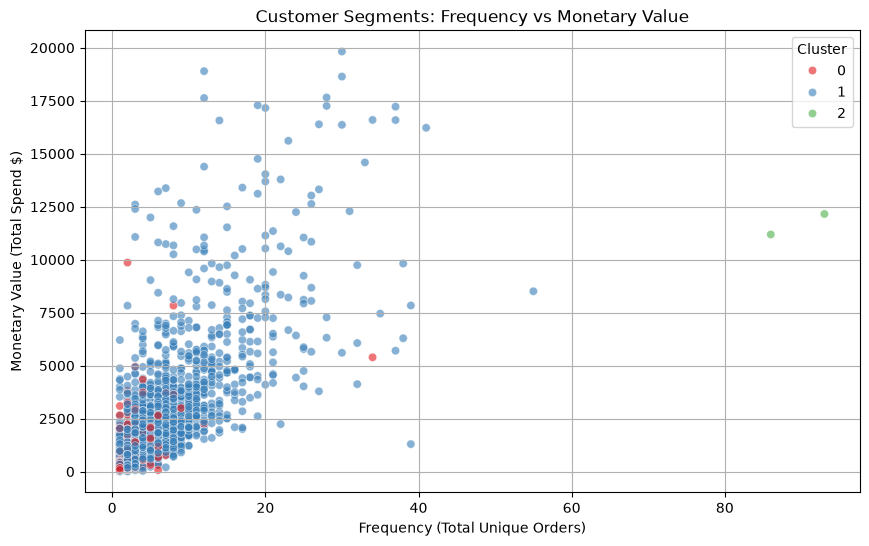

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filter out extreme multi-millionaire outliers just for the visual chart so it scales nicely
plot_data = rfm_data[rfm_data['Monetary'] < rfm_data['Monetary'].quantile(0.99)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_data, 
    x='Frequency', 
    y='Monetary', 
    hue='Cluster', 
    palette='Set1', 
    alpha=0.6
)
plt.title('Customer Segments: Frequency vs Monetary Value')
plt.xlabel('Frequency (Total Unique Orders)')
plt.ylabel('Monetary Value (Total Spend $)')
plt.grid(True)
plt.show()

In [40]:
### Define the business names for each cluster based on your graph
cluster_map = {
    2: "Ultra-Whales (Outliers)",
    1: "Core Spenders & VIPs",
    0: "Low-Value / Quiet Shoppers"
}
rfm_data['Segment_Name'] = rfm_data['Cluster'].map(cluster_map)
rfm_data[['Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment_Name']].head()

,Recency,Frequency,Monetary,Cluster,Segment_Name
CustomerID,,,,,
12346.0,326,1,77183.60,0,Low-Value / Quiet Shoppers
12347.0,2,7,4310.00,1,Core Spenders & VIPs
12348.0,75,4,1797.24,1,Core Spenders & VIPs
12349.0,19,1,1757.55,1,Core Spenders & VIPs
12350.0,310,1,334.40,0,Low-Value / Quiet Shoppers


In [41]:
# Save your final segmentation to a CSV file on your computer
rfm_data.to_csv("customer_segments_final.csv")